In [6]:
import pandas as pd

df = pd.read_csv("sleep.csv")
categorical_df = df.select_dtypes(exclude="number")
numerical_df = df.select_dtypes(include="number")

# check we didn't miss anything along the way
assert len(df.columns.to_list()) == len(categorical_df.columns.to_list()) + len(numerical_df.columns.to_list())

print(categorical_df.columns)
print(numerical_df.columns)

Index(['user_id', 'gender', 'occupation_type', 'chronotype',
       'primary_bedtime_app', 'sleep_debt_category'],
      dtype='str')
Index(['age', 'bedtime_phone_minutes', 'screen_brightness_pct',
       'blue_light_filter_active', 'caffeine_post_5pm_mg',
       'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours',
       'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes',
       'next_day_fatigue_score'],
      dtype='str')


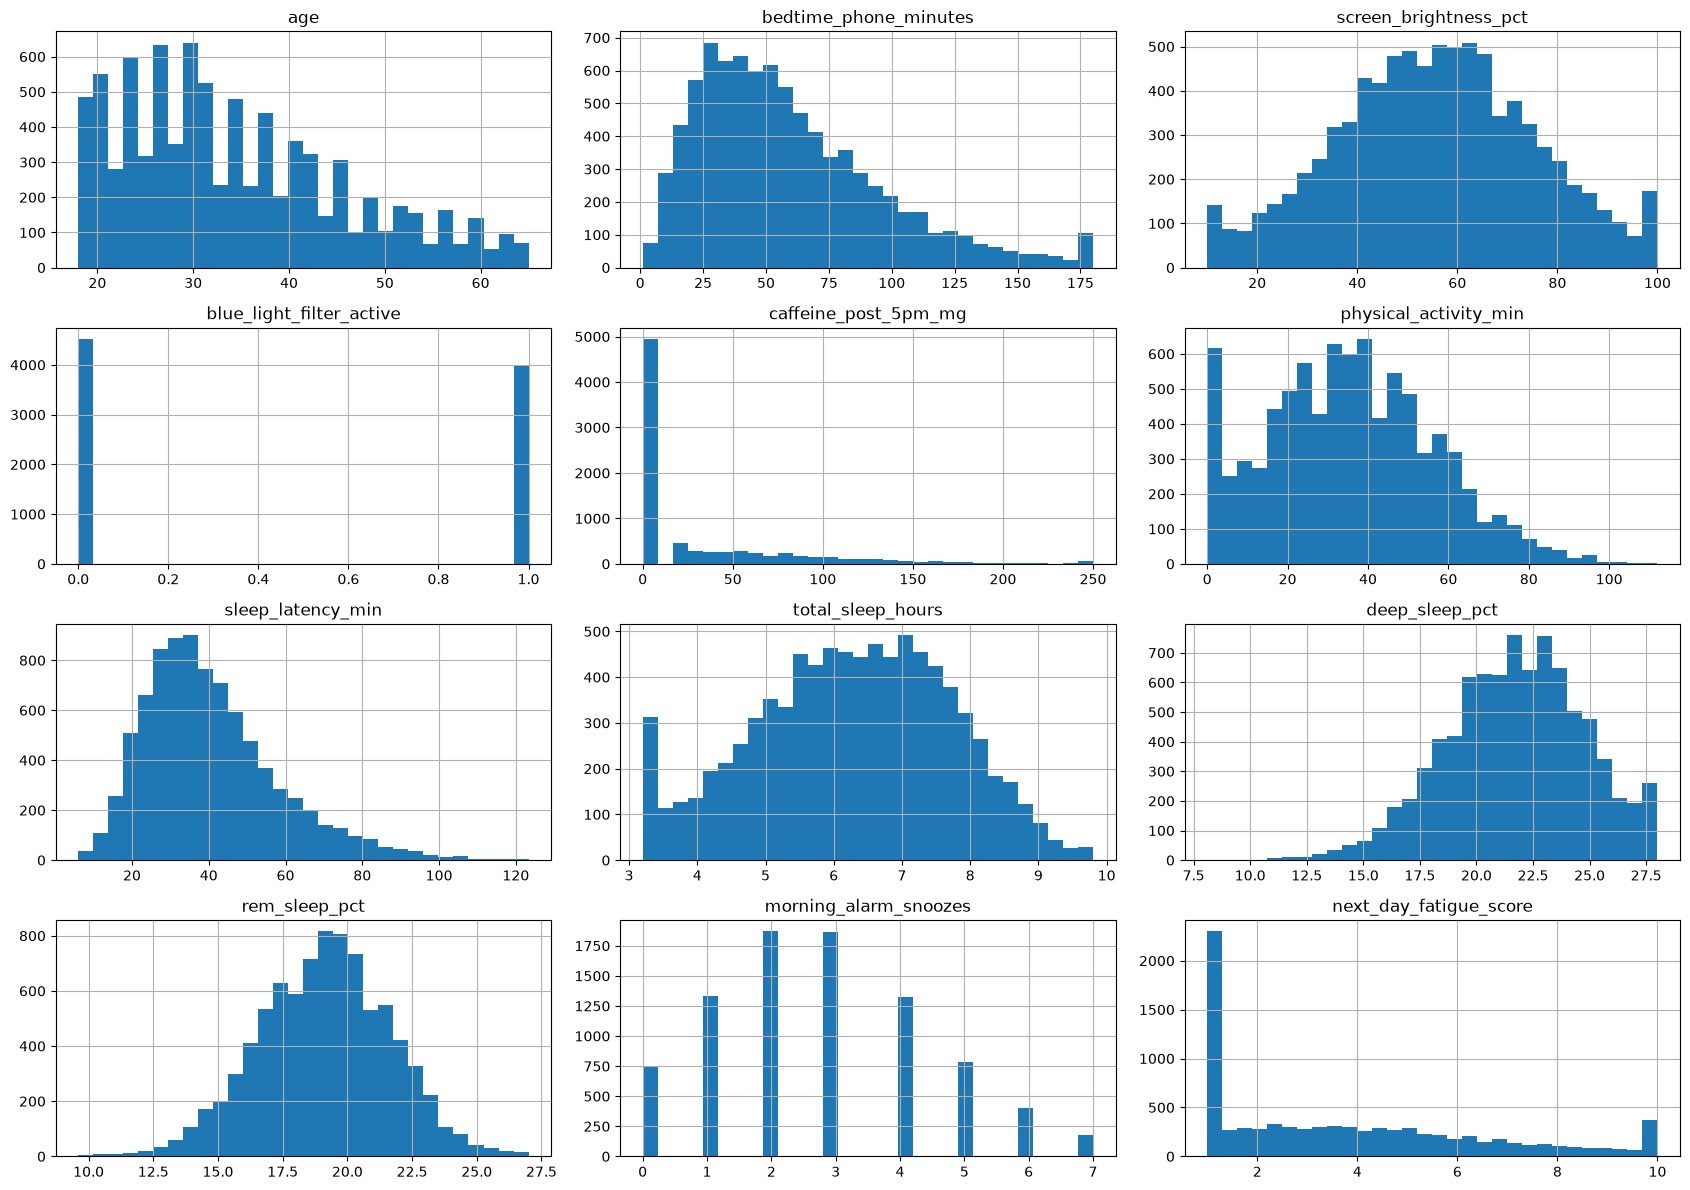

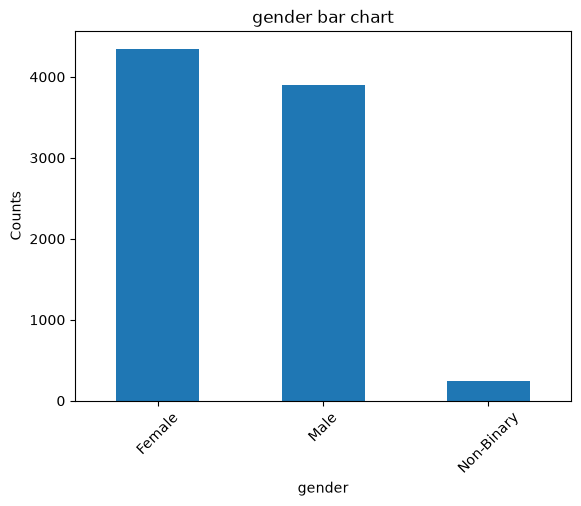

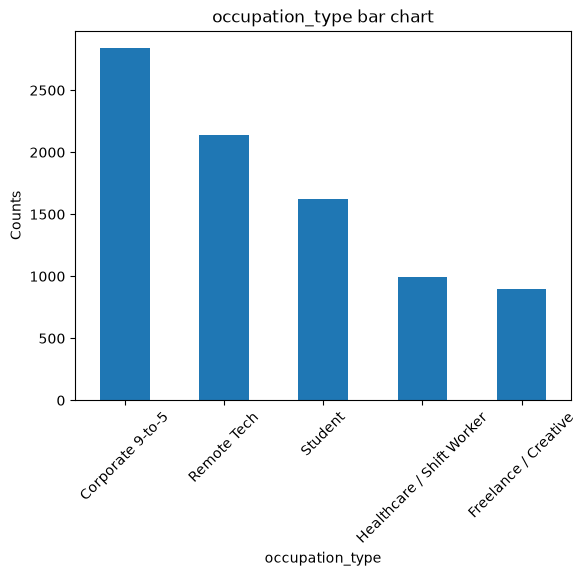

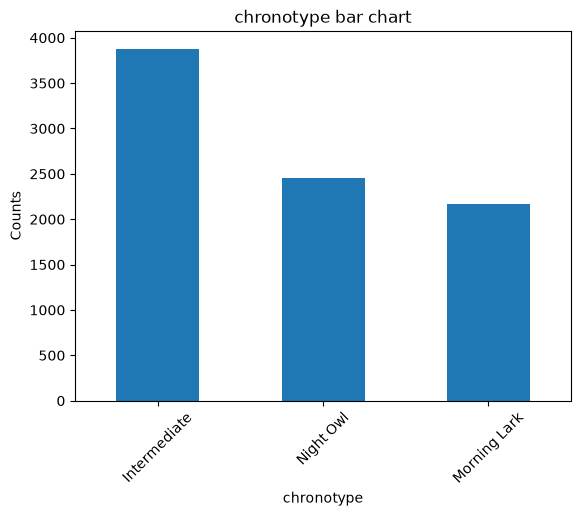

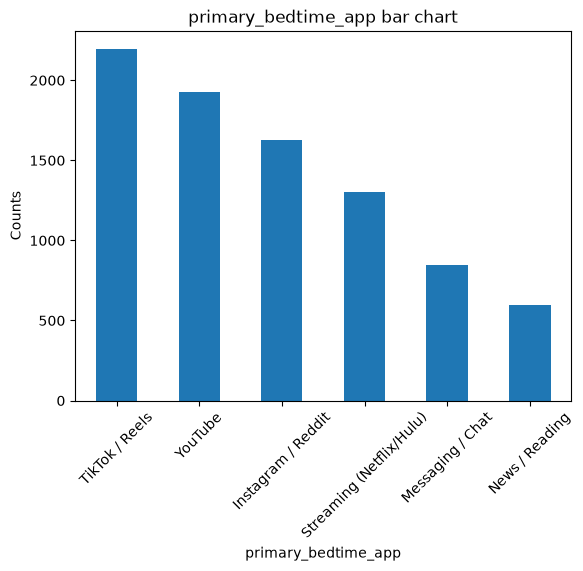

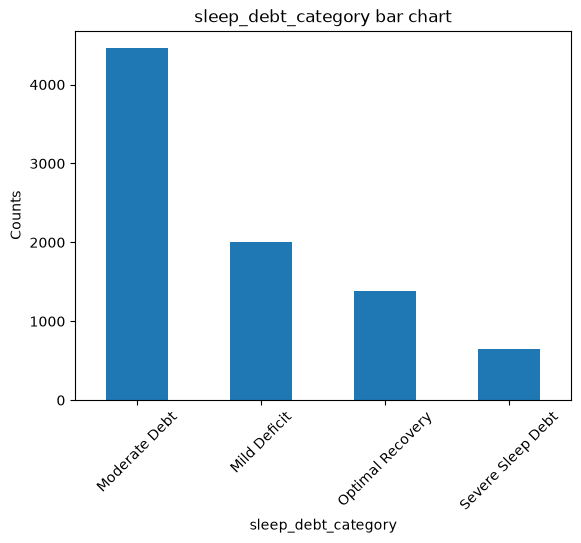

In [7]:
import matplotlib.pyplot as plt

# for name, _ in numerical_df.items():
#     if name.lower() == "id":
#         continue
#     numerical_df[name].hist(bins=30, edgecolor="black")
#     plt.title(f"{name} historgram")
#     plt.xlabel(name)
#     plt.ylabel("Counts")
#     plt.grid(False)
#     plt.show()

# this creates a grid of graphs instead of several big ones
numerical_df.hist(figsize=(17, 12), bins=30)
plt.tight_layout()
plt.show()

# grid of graphs is not as straight forward for bar plots, so here we do create several big ones
for name, _ in categorical_df.items():
    if name == "user_id":
        continue
    categorical_df[name].value_counts().plot(kind="bar", rot=45)
    plt.title(f"{name} bar chart")
    plt.xlabel(name)
    plt.ylabel("Counts")
    plt.grid(False)
    plt.show()

In [3]:
# Παρατηρούμε ότι οι "caffeine_post_5pm_mg" και "next_day_fatique_score" είναι μη-ισορροπημηνες κλάσσεις. Συγκεκριμένα:
# caffeine_post_5pm_mg: Η συντριπτική πλειοψηφία δηλώνει μηδενική κατανάλωση καφέ μετά τις 5 το απόγευμα
# next_day_fatique_score: Οι περισσότεροι δηλώνουν χαμηλό fatique score σύμφωνα με το διάγραμμα

In [4]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from math import sqrt

# the Arrival Delay column has a few NaN rows, so we're going to drop them.
# their count is quite low, less than 0.5%

nan_pct = df.isna().sum()[lambda s: s > 0] / len(df) * 100
if (nan_pct > 0.5).any():
    raise Exception("Too many rows are NaN")

df = df.dropna()

Y = LabelEncoder().fit_transform(df["Satisfaction"])

train_pct = 0.7
test_pct = 0.3
x_train, x_test, y_train, y_test = train_test_split(df, Y, test_size=test_pct, random_state=0)

ct = ColumnTransformer(
    transformers=[
        ("ordinal", OrdinalEncoder(categories=[["Economy", "Economy Plus", "Business"]]), ["Class"]),
        # for columns like Gender which is binary we can drop one of the two columns for efficiency
        ("onehot", OneHotEncoder(drop="if_binary"), ["Type of Travel", "Gender", "Customer Type"]),

        # get the numerical columns names and pass them to StandardScaler
        # We have to do scaling to the numerical columns because their values differ
        # by many orders of magnitude - for example the leg room goes from 0 to 5, 
        # whereas flight distance goes from 0 to 5000
        ("scaling", StandardScaler(), numerical_df.columns.drop(["ID"])),
        
        # drop columns we don't want in our training
        ("drop", "drop", ["Satisfaction", "ID"])
    ],
    remainder="passthrough",
)

results = []
for w in ["distance", "uniform"]:
    for i in [3, 5, 15, 51, 151, int(sqrt(len(x_train)))]:
    # for i in [3, 5]:
        pipeline = Pipeline([
            ("preprocess", ct),
            ("train", KNeighborsClassifier(n_neighbors=i, weights=w))
        ])

        pipeline.fit(x_train, y_train)
        train_score = pipeline.score(x_train, y_train)
        test_score = pipeline.score(x_test, y_test)
        # print(f"Weight: {w} - Neighbors: {i} - train score: {train_score} - test score: {test_score}")
        print(f"Running for weight: {w} and neighbors: {i}")
        results.append({
            "weight": w,
            "neighbors": i,
            "test_score": test_score,
            "train_score": train_score,
        })

res_df = pd.DataFrame(results)

print("============================")
print("Results: ")
print(res_df)

print("============================")
print("Max training score for: ")
print()
print(res_df.loc[res_df["test_score"].idxmax()])

Running for weight: distance and neighbors: 3
Running for weight: distance and neighbors: 5
Running for weight: distance and neighbors: 15
Running for weight: distance and neighbors: 51
Running for weight: distance and neighbors: 151
Running for weight: distance and neighbors: 301
Running for weight: uniform and neighbors: 3
Running for weight: uniform and neighbors: 5
Running for weight: uniform and neighbors: 15
Running for weight: uniform and neighbors: 51
Running for weight: uniform and neighbors: 151
Running for weight: uniform and neighbors: 301
Results: 
      weight  neighbors  test_score  train_score
0   distance          3    0.924190     1.000000
1   distance          5    0.927510     1.000000
2   distance         15    0.927639     1.000000
3   distance         51    0.921693     1.000000
4   distance        151    0.911808     1.000000
5   distance        301    0.903751     1.000000
6    uniform          3    0.924344     0.958219
7    uniform          5    0.927665     

In [ ]:
# Παρατηρούμε ότι ο καλύτερος συνδυασμός είναι για uniform weights με 5 neighbors, 
# καθώς ήταν αυτός με την καλύτερη επίδοση στα training data 